<a href="https://colab.research.google.com/github/dilarabcde/acrima-glaucoma-detection/blob/main/02_ACRIMA_CNN_Models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [13]:

from google.colab import drive
from pathlib import Path
import pandas as pd
import torch

# Google Drive'ı bağla
drive.mount('/content/drive')

# Proje klasörü
ROOT = Path('/content/drive/MyDrive/ACRIMA_Glaucoma_Project')

# Kaydedilen veri bölmelerini oku
train_df = pd.read_csv(ROOT / 'data/splits_v3/train.csv')
val_df = pd.read_csv(ROOT / 'data/splits_v3/val.csv')

print("Training:", len(train_df))
print("Validation:", len(val_df))

# PyTorch ve GPU kontrolü
print("PyTorch:", torch.__version__)
print("GPU kullanılabilir mi?", torch.cuda.is_available())


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Training: 502
Validation: 102
PyTorch: 2.14.1+cpu
GPU kullanılabilir mi? False


In [14]:

import zipfile
from pathlib import Path

# Veri setinin ZIP dosyası
zip_path = ROOT / "Database.zip"

# Colab'ın geçici klasörü
extract_path = Path("/content/acrima_data")

extract_path.mkdir(parents=True, exist_ok=True)

# ZIP dosyasını aç
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

# Görüntü klasörü
image_dir = extract_path / "Database" / "Images"

print("Görüntü klasörü mevcut mu?", image_dir.exists())

# Görüntüleri say
image_files = [
    p for p in image_dir.iterdir()
    if p.is_file() and p.suffix.lower() == ".jpg"
]

print("Toplam görüntü:", len(image_files))


Görüntü klasörü mevcut mu? True
Toplam görüntü: 705


In [15]:

import torch
from torchvision import transforms

# Tekrar üretilebilirlik için
torch.manual_seed(42)

# Eğitim görüntüleri için dönüşümler
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

# Doğrulama görüntüleri için dönüşümler
val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

print("Görüntü dönüşümleri hazır!")


Görüntü dönüşümleri hazır!


In [16]:

from torch.utils.data import Dataset, DataLoader
from PIL import Image

class ACRIMADataset(Dataset):

    def __init__(self, dataframe, image_dir, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        dosya_adi = self.dataframe.iloc[index]["dosya_adi"]
        sinif = self.dataframe.iloc[index]["sinif"]

        with Image.open(self.image_dir / dosya_adi) as img:
            image = img.convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = 1 if sinif == "Glokom" else 0

        return image, label


train_dataset = ACRIMADataset(
    train_df, image_dir, train_transform
)

val_dataset = ACRIMADataset(
    val_df, image_dir, val_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False
)

print("Training Batch Sayısı:", len(train_loader))
print("Validation Batch Sayısı:", len(val_loader))


Training Batch Sayısı: 32
Validation Batch Sayısı: 7


In [17]:

import torch
import torch.nn as nn

# İlk CNN modelimiz
class SimpleCNN(nn.Module):

    def __init__(self):
        super().__init__()

        # Özellik çıkarma katmanları
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        # Sınıflandırma katmanları
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32, 32),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(32, 2)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


# GPU varsa kullan
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Modeli oluştur
model = SimpleCNN().to(device)

print(model)

# Toplam parametre sayısı
parametre_sayisi = sum(
    p.numel() for p in model.parameters()
)

print("\nToplam parametre:", parametre_sayisi)
print("Kullanılan cihaz:", device)

# Bir eğitim batch'i ile çıktı boyutunu kontrol et
goruntuler, etiketler = next(iter(train_loader))

model.eval()
with torch.no_grad():
    cikti = model(goruntuler.to(device))

print("Giriş boyutu:", goruntuler.shape)
print("Çıkış boyutu:", cikti.shape)


SimpleCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): AdaptiveAvgPool2d(output_size=(1, 1))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=32, out_features=32, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=32, out_features=2, bias=True)
  )
)

Toplam parametre: 6210
Kullanılan cihaz: cpu
Giriş boyutu: torch.Size([16, 3, 224, 224])
Çıkış boyutu: torch.Size([16, 2])


In [6]:
print("Training Batch Sayısı:", len(train_loader))

Training Batch Sayısı: 31


In [18]:

import torch.nn as nn
import torch.optim as optim

# Hata fonksiyonu
criterion = nn.CrossEntropyLoss()

# Optimizasyon algoritması
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

# Eğitim turu sayısı
epochs = 10

print("Loss Function:", criterion)
print("Optimizer: Adam")
print("Learning Rate: 0.001")
print("Epochs:", epochs)


Loss Function: CrossEntropyLoss()
Optimizer: Adam
Learning Rate: 0.001
Epochs: 10


In [10]:

from sklearn.metrics import f1_score
import torch
import numpy as np

# Eğitim sonuçlarını saklayacağız
train_losses = []
val_f1_scores = []

best_f1 = -1.0

# Modelin kaydedileceği klasör
model_dir = ROOT / "models"
model_dir.mkdir(parents=True, exist_ok=True)

# Eğitim döngüsü
for epoch in range(epochs):

    model.train()
    toplam_loss = 0

    # TRAINING
    for goruntuler, etiketler in train_loader:

        goruntuler = goruntuler.to(device)
        etiketler = etiketler.to(device)

        optimizer.zero_grad()

        # Forward
        cikti = model(goruntuler)

        # Loss
        loss = criterion(cikti, etiketler)

        # Backward
        loss.backward()

        # Ağırlıkları güncelle
        optimizer.step()

        toplam_loss += loss.item() * goruntuler.size(0)

    train_loss = toplam_loss / len(train_dataset)

    # VALIDATION
    model.eval()

    gercek = []
    tahmin = []

    with torch.no_grad():
        for goruntuler, etiketler in val_loader:

            goruntuler = goruntuler.to(device)

            cikti = model(goruntuler)
            predicted = torch.argmax(cikti, dim=1)

            gercek.extend(etiketler.numpy())
            tahmin.extend(predicted.cpu().numpy())

    macro_f1 = f1_score(
        gercek,
        tahmin,
        average="macro",
        zero_division=0
    )

    train_losses.append(train_loss)
    val_f1_scores.append(macro_f1)

    # En iyi modeli kaydet
    if macro_f1 > best_f1:
        best_f1 = macro_f1

        torch.save(
            model.state_dict(),
            model_dir / "simple_cnn_v3_best.pth"
        )

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Validation Macro F1: {macro_f1:.4f}"
    )

print("\nEğitim tamamlandı!")
print(f"En iyi Validation Macro F1: {best_f1:.4f}")


Epoch 1/10 | Train Loss: 0.3142 | Validation Macro F1: 0.7922
Epoch 2/10 | Train Loss: 0.3397 | Validation Macro F1: 0.8019
Epoch 3/10 | Train Loss: 0.3262 | Validation Macro F1: 0.7997
Epoch 4/10 | Train Loss: 0.3027 | Validation Macro F1: 0.8096
Epoch 5/10 | Train Loss: 0.2669 | Validation Macro F1: 0.8292
Epoch 6/10 | Train Loss: 0.2815 | Validation Macro F1: 0.8446
Epoch 7/10 | Train Loss: 0.2742 | Validation Macro F1: 0.8393
Epoch 8/10 | Train Loss: 0.2757 | Validation Macro F1: 0.8486
Epoch 9/10 | Train Loss: 0.2874 | Validation Macro F1: 0.8656
Epoch 10/10 | Train Loss: 0.2809 | Validation Macro F1: 0.8733

Eğitim tamamlandı!
En iyi Validation Macro F1: 0.8733


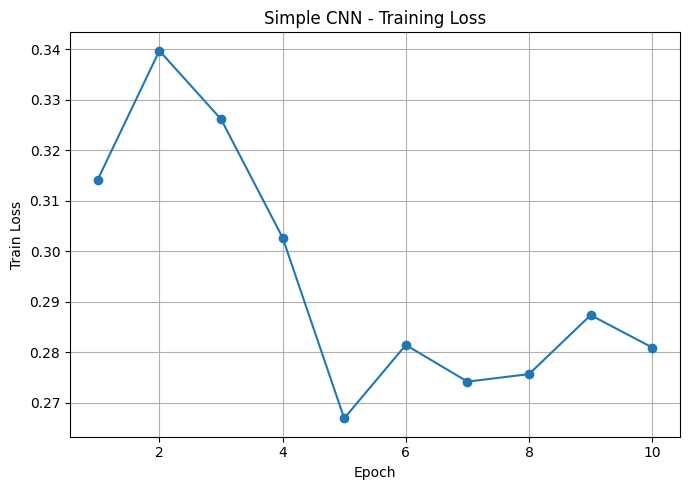

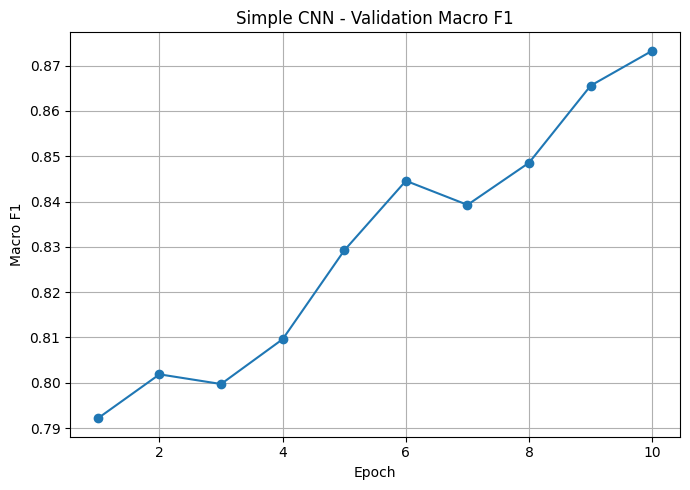

Eğitim geçmişi ve grafikler kaydedildi!


In [19]:

import matplotlib.pyplot as plt
import pandas as pd

# Epoch numaraları
epoch_numbers = range(1, len(train_losses) + 1)

# Eğitim geçmişini kaydet
history_df = pd.DataFrame({
    "epoch": list(epoch_numbers),
    "train_loss": train_losses,
    "val_macro_f1": val_f1_scores
})

history_df.to_csv(
    ROOT / "results" / "simple_cnn_history.csv",
    index=False
)

# Train Loss grafiği
plt.figure(figsize=(7, 5))
plt.plot(epoch_numbers, train_losses, marker="o")
plt.title("Simple CNN - Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Train Loss")
plt.grid(True)
plt.tight_layout()
plt.savefig(
    ROOT / "figures" / "simple_cnn_train_loss.png",
    dpi=300
)
plt.show()

# Validation Macro F1 grafiği
plt.figure(figsize=(7, 5))
plt.plot(epoch_numbers, val_f1_scores, marker="o")
plt.title("Simple CNN - Validation Macro F1")
plt.xlabel("Epoch")
plt.ylabel("Macro F1")
plt.grid(True)
plt.tight_layout()
plt.savefig(
    ROOT / "figures" / "simple_cnn_val_f1.png",
    dpi=300
)
plt.show()

print("Eğitim geçmişi ve grafikler kaydedildi!")


Validation Accuracy: 0.8529
Validation Macro F1: 0.8497

Classification Report:
              precision    recall  f1-score   support

      Normal     0.8571    0.8000    0.8276        45
      Glokom     0.8500    0.8947    0.8718        57

    accuracy                         0.8529       102
   macro avg     0.8536    0.8474    0.8497       102
weighted avg     0.8532    0.8529    0.8523       102



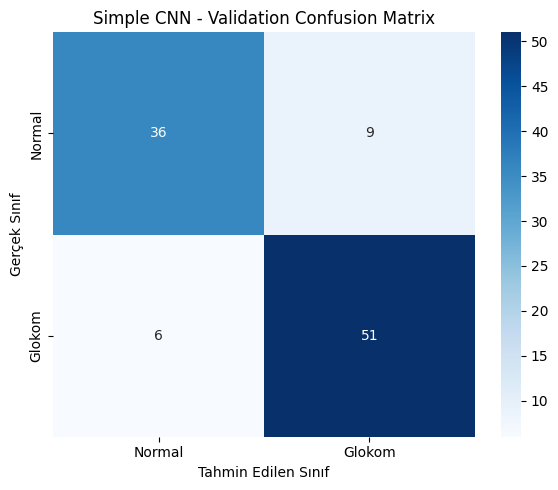

In [20]:

import torch
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# En iyi modelin ağırlıklarını yükle
model.load_state_dict(
    torch.load(
        ROOT / "models" / "simple_cnn_best.pth",
        map_location=device,
        weights_only=True
    )
)

model.eval()

gercek = []
tahmin = []

# Validation görüntülerinde tahmin yap
with torch.no_grad():
    for goruntuler, etiketler in val_loader:

        goruntuler = goruntuler.to(device)

        cikti = model(goruntuler)
        predicted = torch.argmax(cikti, dim=1)

        gercek.extend(etiketler.numpy())
        tahmin.extend(predicted.cpu().numpy())

# Performans metrikleri
accuracy = accuracy_score(gercek, tahmin)
macro_f1 = f1_score(gercek, tahmin, average="macro")

print("Validation Accuracy:", round(accuracy, 4))
print("Validation Macro F1:", round(macro_f1, 4))

print("\nClassification Report:")
print(classification_report(
    gercek,
    tahmin,
    target_names=["Normal", "Glokom"],
    digits=4
))

# Confusion Matrix
cm = confusion_matrix(gercek, tahmin, labels=[0, 1])

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Glokom"],
    yticklabels=["Normal", "Glokom"]
)

plt.title("Simple CNN - Validation Confusion Matrix")
plt.xlabel("Tahmin Edilen Sınıf")
plt.ylabel("Gerçek Sınıf")
plt.tight_layout()
plt.show()


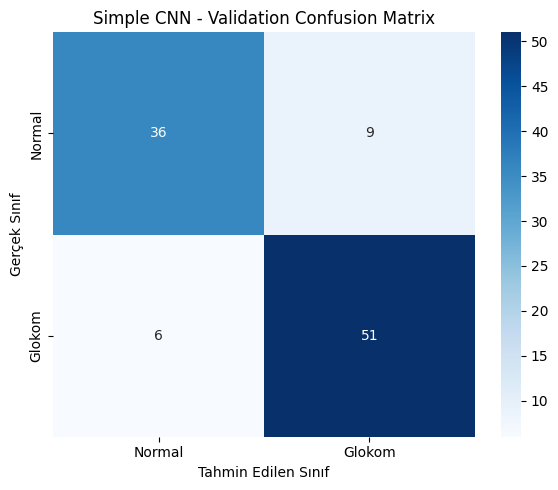

CNN sonuçları ve hata matrisi kaydedildi!
       model veri_kumesi  accuracy  macro_f1  balanced_accuracy  seed  \
0  SimpleCNN  validation  0.852941  0.849691           0.847368    42   

   best_epoch  
0           9  


In [21]:

import pandas as pd
from sklearn.metrics import balanced_accuracy_score

# Sonuçları hesapla
balanced_acc = balanced_accuracy_score(gercek, tahmin)

# Sonuç tablosu
cnn_sonuclar = pd.DataFrame([{
    "model": "SimpleCNN",
    "veri_kumesi": "validation",
    "accuracy": accuracy,
    "macro_f1": macro_f1,
    "balanced_accuracy": balanced_acc,
    "seed": 42,
    "best_epoch": 9
}])

# CSV olarak kaydet
cnn_sonuclar.to_csv(
    ROOT / "results" / "simple_cnn_results.csv",
    index=False
)

# Confusion Matrix grafiğini kaydet
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Glokom"],
    yticklabels=["Normal", "Glokom"]
)

plt.title("Simple CNN - Validation Confusion Matrix")
plt.xlabel("Tahmin Edilen Sınıf")
plt.ylabel("Gerçek Sınıf")

plt.tight_layout()
plt.savefig(
    ROOT / "figures" / "simple_cnn_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("CNN sonuçları ve hata matrisi kaydedildi!")
print(cnn_sonuclar)


In [22]:

import torch
import torch.nn as nn

# İkinci CNN modelimiz
class DeepCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(32, 2)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


deep_model = DeepCNN().to(device)

# Parametre sayısını hesapla
parametre_sayisi = sum(
    p.numel() for p in deep_model.parameters()
)

print("DeepCNN parametre sayısı:", parametre_sayisi)
print("Kullanılan cihaz:", device)

# Giriş ve çıkış kontrolü
deep_model.eval()

with torch.no_grad():
    cikti = deep_model(goruntuler.to(device))

print("Giriş boyutu:", goruntuler.shape)
print("Çıkış boyutu:", cikti.shape)


DeepCNN parametre sayısı: 25954
Kullanılan cihaz: cpu
Giriş boyutu: torch.Size([6, 3, 224, 224])
Çıkış boyutu: torch.Size([6, 2])


In [23]:

from sklearn.metrics import f1_score
import torch
import torch.nn as nn
import torch.optim as optim

# DeepCNN eğitim ayarları
deep_criterion = nn.CrossEntropyLoss()

deep_optimizer = optim.Adam(
    deep_model.parameters(),
    lr=0.001
)

deep_epochs = 10

deep_train_losses = []
deep_val_f1_scores = []

deep_best_f1 = -1.0
deep_best_epoch = 0

# Eğitim döngüsü
for epoch in range(deep_epochs):

    deep_model.train()
    toplam_loss = 0

    # TRAINING
    for goruntuler, etiketler in train_loader:

        goruntuler = goruntuler.to(device)
        etiketler = etiketler.to(device)

        deep_optimizer.zero_grad()

        cikti = deep_model(goruntuler)
        loss = deep_criterion(cikti, etiketler)

        loss.backward()
        deep_optimizer.step()

        toplam_loss += loss.item() * goruntuler.size(0)

    train_loss = toplam_loss / len(train_dataset)

    # VALIDATION
    deep_model.eval()

    gercek = []
    tahmin = []

    with torch.no_grad():
        for goruntuler, etiketler in val_loader:

            goruntuler = goruntuler.to(device)

            cikti = deep_model(goruntuler)
            predicted = torch.argmax(cikti, dim=1)

            gercek.extend(etiketler.numpy())
            tahmin.extend(predicted.cpu().numpy())

    macro_f1 = f1_score(
        gercek,
        tahmin,
        average="macro",
        zero_division=0
    )

    deep_train_losses.append(train_loss)
    deep_val_f1_scores.append(macro_f1)

    # En iyi modeli kaydet
    if macro_f1 > deep_best_f1:
        deep_best_f1 = macro_f1
        deep_best_epoch = epoch + 1

        torch.save(
            deep_model.state_dict(),
            ROOT / "models" / "deep_cnn_v3_best.pth"
        )

    print(
        f"Epoch {epoch+1}/{deep_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Validation Macro F1: {macro_f1:.4f}"
    )

print("\nDeepCNN eğitimi tamamlandı!")
print("En iyi epoch:", deep_best_epoch)
print(f"En iyi Validation Macro F1: {deep_best_f1:.4f}")


Epoch 1/10 | Train Loss: 0.4567 | Validation Macro F1: 0.8573
Epoch 2/10 | Train Loss: 0.2894 | Validation Macro F1: 0.8497
Epoch 3/10 | Train Loss: 0.2345 | Validation Macro F1: 0.8766
Epoch 4/10 | Train Loss: 0.2429 | Validation Macro F1: 0.8904
Epoch 5/10 | Train Loss: 0.2060 | Validation Macro F1: 0.7532
Epoch 6/10 | Train Loss: 0.2339 | Validation Macro F1: 0.8233
Epoch 7/10 | Train Loss: 0.2661 | Validation Macro F1: 0.8864
Epoch 8/10 | Train Loss: 0.2229 | Validation Macro F1: 0.9086
Epoch 9/10 | Train Loss: 0.1986 | Validation Macro F1: 0.9502
Epoch 10/10 | Train Loss: 0.1795 | Validation Macro F1: 0.9086

DeepCNN eğitimi tamamlandı!
En iyi epoch: 9
En iyi Validation Macro F1: 0.9502


DeepCNN Validation Accuracy: 0.951
DeepCNN Validation Macro F1: 0.9502

Classification Report:
              precision    recall  f1-score   support

      Normal     0.9545    0.9333    0.9438        45
      Glokom     0.9483    0.9649    0.9565        57

    accuracy                         0.9510       102
   macro avg     0.9514    0.9491    0.9502       102
weighted avg     0.9510    0.9510    0.9509       102



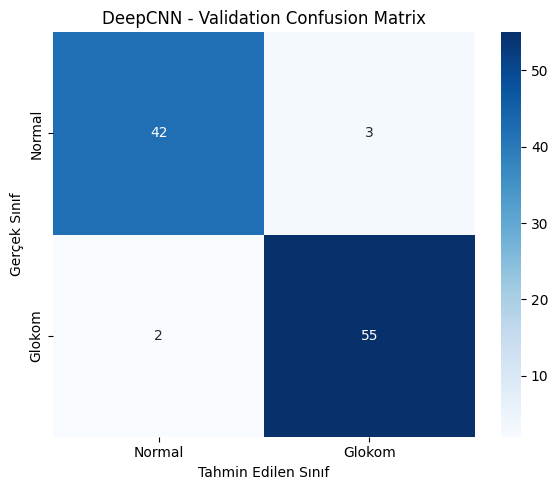

In [24]:

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import torch
import matplotlib.pyplot as plt
import seaborn as sns

# En iyi DeepCNN modelini yükle
deep_model.load_state_dict(
    torch.load(
        ROOT / "models" / "deep_cnn_best.pth",
        map_location=device,
        weights_only=True
    )
)

deep_model.eval()

deep_gercek = []
deep_tahmin = []

# Doğrulama verileriyle tahmin yap
with torch.no_grad():
    for goruntuler, etiketler in val_loader:

        goruntuler = goruntuler.to(device)

        cikti = deep_model(goruntuler)
        predicted = torch.argmax(cikti, dim=1)

        deep_gercek.extend(etiketler.numpy())
        deep_tahmin.extend(predicted.cpu().numpy())

# Performansı hesapla
deep_accuracy = accuracy_score(deep_gercek, deep_tahmin)
deep_macro_f1 = f1_score(
    deep_gercek,
    deep_tahmin,
    average="macro"
)

print("DeepCNN Validation Accuracy:", round(deep_accuracy, 4))
print("DeepCNN Validation Macro F1:", round(deep_macro_f1, 4))

print("\nClassification Report:")
print(classification_report(
    deep_gercek,
    deep_tahmin,
    target_names=["Normal", "Glokom"],
    digits=4
))

# Hata matrisi
deep_cm = confusion_matrix(
    deep_gercek,
    deep_tahmin,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    deep_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Glokom"],
    yticklabels=["Normal", "Glokom"]
)

plt.title("DeepCNN - Validation Confusion Matrix")
plt.xlabel("Tahmin Edilen Sınıf")
plt.ylabel("Gerçek Sınıf")

plt.tight_layout()
plt.show()


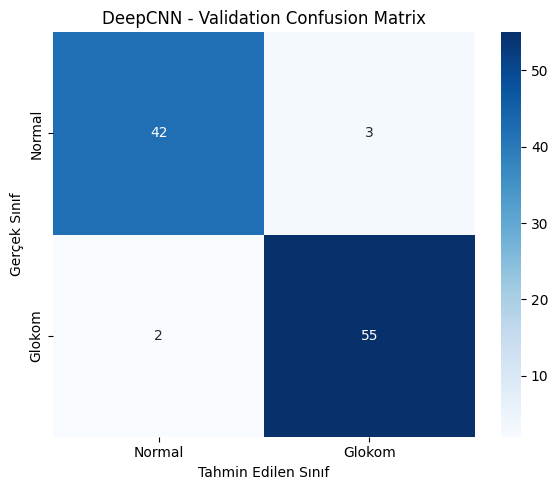

DeepCNN sonuçları kaydedildi!
     model veri_kumesi  accuracy  macro_f1  balanced_accuracy  seed  \
0  DeepCNN  validation   0.95098  0.950171           0.949123    42   

   best_epoch  
0           9  


In [25]:

import pandas as pd
from sklearn.metrics import balanced_accuracy_score

# DeepCNN sonuçlarını hesapla
deep_balanced_acc = balanced_accuracy_score(
    deep_gercek, deep_tahmin
)

deep_sonuclar = pd.DataFrame([{
    "model": "DeepCNN",
    "veri_kumesi": "validation",
    "accuracy": deep_accuracy,
    "macro_f1": deep_macro_f1,
    "balanced_accuracy": deep_balanced_acc,
    "seed": 42,
    "best_epoch": deep_best_epoch
}])

# Sonuçları kaydet
deep_sonuclar.to_csv(
    ROOT / "results" / "deep_cnn_results.csv",
    index=False
)

# Eğitim geçmişini kaydet
deep_history = pd.DataFrame({
    "epoch": range(1, len(deep_train_losses) + 1),
    "train_loss": deep_train_losses,
    "val_macro_f1": deep_val_f1_scores
})

deep_history.to_csv(
    ROOT / "results" / "deep_cnn_history.csv",
    index=False
)

# Hata matrisini kaydet
plt.figure(figsize=(6, 5))

sns.heatmap(
    deep_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Glokom"],
    yticklabels=["Normal", "Glokom"]
)

plt.title("DeepCNN - Validation Confusion Matrix")
plt.xlabel("Tahmin Edilen Sınıf")
plt.ylabel("Gerçek Sınıf")

plt.tight_layout()
plt.savefig(
    ROOT / "figures" / "deep_cnn_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("DeepCNN sonuçları kaydedildi!")
print(deep_sonuclar)


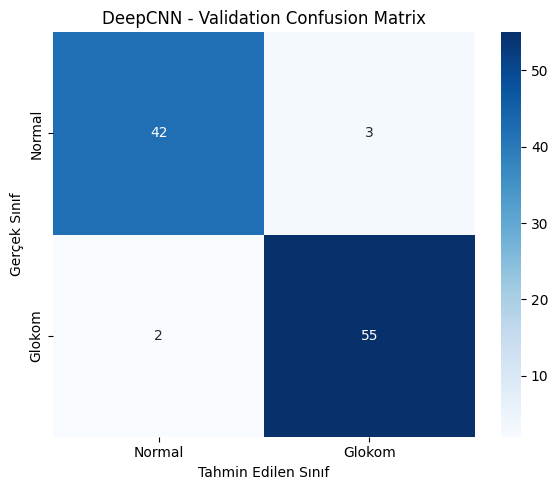

DeepCNN sonuçları kaydedildi!
     model veri_kumesi  accuracy  macro_f1  balanced_accuracy  seed  \
0  DeepCNN  validation   0.95098  0.950171           0.949123    42   

   best_epoch  
0           9  


In [26]:

import pandas as pd
from sklearn.metrics import balanced_accuracy_score

# DeepCNN sonuçlarını hesapla
deep_balanced_acc = balanced_accuracy_score(
    deep_gercek, deep_tahmin
)

deep_sonuclar = pd.DataFrame([{
    "model": "DeepCNN",
    "veri_kumesi": "validation",
    "accuracy": deep_accuracy,
    "macro_f1": deep_macro_f1,
    "balanced_accuracy": deep_balanced_acc,
    "seed": 42,
    "best_epoch": deep_best_epoch
}])

# Sonuçları kaydet
deep_sonuclar.to_csv(
    ROOT / "results" / "deep_cnn_results.csv",
    index=False
)

# Eğitim geçmişini kaydet
deep_history = pd.DataFrame({
    "epoch": range(1, len(deep_train_losses) + 1),
    "train_loss": deep_train_losses,
    "val_macro_f1": deep_val_f1_scores
})

deep_history.to_csv(
    ROOT / "results" / "deep_cnn_history.csv",
    index=False
)

# Hata matrisini kaydet
plt.figure(figsize=(6, 5))

sns.heatmap(
    deep_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Glokom"],
    yticklabels=["Normal", "Glokom"]
)

plt.title("DeepCNN - Validation Confusion Matrix")
plt.xlabel("Tahmin Edilen Sınıf")
plt.ylabel("Gerçek Sınıf")

plt.tight_layout()
plt.savefig(
    ROOT / "figures" / "deep_cnn_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("DeepCNN sonuçları kaydedildi!")
print(deep_sonuclar)


In [27]:

import pandas as pd

# Kaydettiğimiz model sonuçlarını oku
baseline = pd.read_csv(
    ROOT / "results" / "baseline_results.csv"
)

simple = pd.read_csv(
    ROOT / "results" / "simple_cnn_results.csv"
)

deep = pd.read_csv(
    ROOT / "results" / "deep_cnn_results.csv"
)

# Sonuçları tek tabloda birleştir
karsilastirma = pd.concat(
    [baseline, simple, deep],
    ignore_index=True
)

# Macro F1'e göre büyükten küçüğe sırala
karsilastirma = karsilastirma.sort_values(
    by="macro_f1",
    ascending=False
)

# CSV dosyasına kaydet
karsilastirma.to_csv(
    ROOT / "results" / "model_comparison.csv",
    index=False
)

print("Model karşılaştırma tablosu:")
print(karsilastirma)


Model karşılaştırma tablosu:
       model veri_kumesi  accuracy  macro_f1  balanced_accuracy  seed  \
2    DeepCNN  validation  0.950980  0.950171           0.949123    42   
1  SimpleCNN  validation  0.852941  0.849691           0.847368    42   
0    HOG_SVM  validation  0.811321  0.805718           0.802899    42   

   best_epoch  
2         9.0  
1         9.0  
0         NaN  


In [28]:
for ad in ["simple_cnn_v3_best.pth", "deep_cnn_v3_best.pth"]:
    yol = model_dir / ad
    print(ad, ":", "Kayıtlı" if yol.exists() else "Bulunamadı")

simple_cnn_v3_best.pth : Kayıtlı
deep_cnn_v3_best.pth : Kayıtlı


In [29]:

from pathlib import Path
from datetime import datetime

for ad in [
    "simple_cnn_v3_best.pth",
    "deep_cnn_v3_best.pth"
]:
    yol = ROOT / "models" / ad

    print("\nModel:", ad)
    print("Mevcut:", yol.exists())

    if yol.exists():
        print("Boyut (MB):", round(yol.stat().st_size / 1024**2, 2))
        print(
            "Son kayıt:",
            datetime.fromtimestamp(
                yol.stat().st_mtime
            ).strftime("%Y-%m-%d %H:%M:%S")
        )



Model: simple_cnn_v3_best.pth
Mevcut: True
Boyut (MB): 0.03
Son kayıt: 2026-11-24 18:34:15

Model: deep_cnn_v3_best.pth
Mevcut: True
Boyut (MB): 0.11
Son kayıt: 2026-11-24 19:14:22


In [30]:

print("Aktif veri ayrımı:")
print("Training:", len(train_df))
print("Validation:", len(val_df))

print("\nSimpleCNN:")
if "best_f1" in globals():
    print("En iyi Macro F1:", round(best_f1, 4))
else:
    print("Eğitim değişkeni bulunamadı.")

print("\nDeepCNN:")
if "deep_best_f1" in globals():
    print("En iyi Macro F1:", round(deep_best_f1, 4))
else:
    print("Eğitim değişkeni bulunamadı.")

if "deep_best_epoch" in globals():
    print("En iyi epoch:", deep_best_epoch)


Aktif veri ayrımı:
Training: 502
Validation: 102

SimpleCNN:
En iyi Macro F1: 0.8733

DeepCNN:
En iyi Macro F1: 0.9502
En iyi epoch: 9


In [31]:

print("Train CSV:", len(train_df))
print("Validation CSV:", len(val_df))

print("\nDataLoader kontrolü:")
print("Train Dataset:", len(train_loader.dataset))
print("Validation Dataset:", len(val_loader.dataset))

assert len(train_loader.dataset) == 502
assert len(val_loader.dataset) == 102

print("\nDataLoader boyutları splits_v3 ile uyumlu!")


Train CSV: 502
Validation CSV: 102

DataLoader kontrolü:
Train Dataset: 502
Validation Dataset: 102

DataLoader boyutları splits_v3 ile uyumlu!


In [32]:

print("Training Dataset türü:")
print(type(train_loader.dataset).__name__)

print("\nTraining Dataset değişkenleri:")
print(vars(train_loader.dataset).keys())

print("\nValidation Dataset değişkenleri:")
print(vars(val_loader.dataset).keys())


Training Dataset türü:
ACRIMADataset

Training Dataset değişkenleri:
dict_keys(['dataframe', 'image_dir', 'transform'])

Validation Dataset değişkenleri:
dict_keys(['dataframe', 'image_dir', 'transform'])


In [33]:

# Training görüntülerini karşılaştır
train_csv = set(train_df["dosya_adi"])
train_dataset = set(
    train_loader.dataset.dataframe["dosya_adi"]
)

# Validation görüntülerini karşılaştır
val_csv = set(val_df["dosya_adi"])
val_dataset = set(
    val_loader.dataset.dataframe["dosya_adi"]
)

print("Training listeleri aynı mı?",
      train_csv == train_dataset)

print("Validation listeleri aynı mı?",
      val_csv == val_dataset)

assert train_csv == train_dataset
assert val_csv == val_dataset

print("\nDataLoader görüntü listeleri splits_v3 ile eşleşiyor!")


Training listeleri aynı mı? True
Validation listeleri aynı mı? True

DataLoader görüntü listeleri splits_v3 ile eşleşiyor!


In [34]:

import pandas as pd

sonuclar_v3 = pd.DataFrame([
    {
        "model": "SimpleCNN",
        "split": "splits_v3",
        "best_epoch": 10,
        "validation_macro_f1": 0.8733,
        "model_file": "simple_cnn_v3_best.pth"
    },
    {
        "model": "DeepCNN",
        "split": "splits_v3",
        "best_epoch": 9,
        "validation_macro_f1": 0.9502,
        "model_file": "deep_cnn_v3_best.pth"
    }
])

kayit_yolu = ROOT / "results" / "cnn_comparison_v3.csv"
kayit_yolu.parent.mkdir(parents=True, exist_ok=True)

sonuclar_v3.to_csv(kayit_yolu, index=False)

print(sonuclar_v3.to_string(index=False))
print("\nKaydedildi:", kayit_yolu)


    model     split  best_epoch  validation_macro_f1             model_file
SimpleCNN splits_v3          10               0.8733 simple_cnn_v3_best.pth
  DeepCNN splits_v3           9               0.9502   deep_cnn_v3_best.pth

Kaydedildi: /content/drive/MyDrive/ACRIMA_Glaucoma_Project/results/cnn_comparison_v3.csv
